# Day 1 — 검산 · 전처리 · 무료 개방일 규칙 · 베이스라인 백테스트

| 항목 | 설정 |
|---|---|
| 예측 단위 | 개소 × 날짜 (23개소) |
| 예측 원점 | 2025-07-01(화)부터 7일 간격 26개 (가이드 예시 표와 같은 설정) |
| 예측 기간 | 원점부터 7일 |
| 근무표 확정 | 원점 전날 (cutoff = origin − 1일) |
| 평가 | 문을 연 날만 (`status == 'open'`), 개소 × 날짜 단위 |
| 1순위 지표 | **개소 단위 MASE** — 개소마다 7일 평균 절대 오차 ÷ 그 개소에서 1주 전 같은 요일 값(lag 7)이 2023-01-01~원점 전날 낸 평균 절대 오차. 원점·개소 평균. WAPE·비용 병기 |
| 평가표 나누기 | 전체 · 특별일(공휴일·무료 개방일 규칙) **있는 주 / 없는 주** |
| 비용 | C_u 60만 원, C_o 15만 원, 1명 = 하루 2,000명, 소수 인원 그대로 |

공통 코드는 `src/hv.py` 에 있습니다. 전체 일정과 지표 선택 근거는 `PLAN.md` 를 봅니다.

> **MASE 를 1순위로 둔 이유**: 하루 관람객이 경복궁 수만 명, 양주온릉 수십 명이라 WAPE 는 큰 개소 오차가 거의 전부를 정합니다. MASE 는 개소마다 「그 개소의 계절 나이브가 평소 내던 오차」로 나눠 크기를 맞춥니다(수업 글로벌 모델 카드). 비용은 원 단위라 큰 개소 중심으로 따로 봅니다.

In [1]:
import sys; sys.path.insert(0, 'src')
import pandas as pd, numpy as np
import hv
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.3f}'.format)
OUT = __import__('pathlib').Path('outputs/day1'); OUT.mkdir(parents=True, exist_ok=True)

## 1. 검산 7개

In [2]:
v, w, c, s = hv.load()
chk = hv.check_anchors(v, w, c)
assert chk['일치'].all(), '검산 불일치 — 다음 단계로 가지 않음'
chk

,항목,읽은 값,anchors,일치
0,관람객 표 행 수,62028,62028,True
1,개소 수,23,23,True
2,total 합,119991391,119991391,True
3,외국인 4열 합,22960148,22960148,True
4,total 이 0 인 행,8832,8832,True
5,날씨 표 행 수,92414,92414,True
6,달력 행 수,4018,4018,True


## 2. 달력 — 2026년까지 확장하고 무료 개방일 규칙 붙이기

`holidays` 0.103 의 `holidays.KR` 로 만든 달력이 제공 달력(2015~2025)과 완전히 같은지 먼저 확인합니다. 같으면 같은 함수로 2026년 권고표 날짜의 달력을 씁니다.

In [3]:
cal = hv.make_calendar('2015-01-01', '2026-12-31')
m = c.merge(cal, on='date', suffixes=('', '_gen'))
diff = {col: int((~((m[col] == m[col + '_gen']) | (m[col].isna() & m[col + '_gen'].isna()))).sum())
        for col in ['weekday', 'holiday_name', 'is_holiday', 'seollal_offset', 'chuseok_offset', 'is_last_wednesday']}
assert sum(diff.values()) == 0, diff
print('제공 달력과 불일치 칸 수:', diff)
cal = hv.add_free_rule(cal)
cal.to_csv(OUT / 'calendar_2015_2026_with_rules.csv', index=False, encoding='utf-8-sig')

제공 달력과 불일치 칸 수: {'weekday': 0, 'holiday_name': 0, 'is_holiday': 0, 'seollal_offset': 0, 'chuseok_offset': 0, 'is_last_wednesday': 0}


**무료 개방일 규칙** (예측에 쓰는 표시 — 달력으로 미리 알 수 있는 것만)

- **명절 연휴**: 설날·추석 당일을 포함해 이어지는 쉬는 날(주말 또는 공휴일) 덩어리 전체
- **문화가 있는 날**: 매월 마지막 수요일

`paid == 0` 이나 유료 비중으로 만든 표시는 예측 시점에 알 수 없으므로 쓰지 않습니다(자주 하는 실수 3·5번). 아래에서 이 규칙이 과거 무료 개방일(가이드 분석용 정의: 유료 비중 15% 미만)을 얼마나 설명하는지 확인합니다.

In [4]:
panel = hv.build_panel(v, cal, s)
print(panel['status'].value_counts().to_dict())

top6 = ['경복궁', '덕수궁', '창덕궁', '창경궁', '종묘', '선릉']
x = panel[(panel['status'] == 'open') & (panel['date'] >= '2023-01-01') & panel['site'].isin(top6)].copy()
x['free_obs'] = (x['paid'] / x['total'] < 0.15).astype(int)
rule_check = x.groupby('site').apply(lambda d: pd.Series({
    '관측 무료일(유료<15%)': d['free_obs'].sum(),
    '규칙 무료일': d['is_free_rule'].sum(),
    '규칙이 맞힌 관측 무료일': (d['free_obs'] & d['is_free_rule']).sum(),
    '재현율': (d['free_obs'] & d['is_free_rule']).sum() / max(d['free_obs'].sum(), 1),
    '정밀도': (d['free_obs'] & d['is_free_rule']).sum() / max(d['is_free_rule'].sum(), 1),
}), include_groups=False).loc[top6]
rule_check

{'open': 53196, 'closed': 8832, 'missing': 1166}


,관측 무료일(유료<15%),규칙 무료일,규칙이 맞힌 관측 무료일,재현율,정밀도
site,,,,,
경복궁,80.000,66.000,65.000,0.812,0.985
덕수궁,170.000,66.000,64.000,0.376,0.970
창덕궁,71.000,66.000,57.000,0.803,0.864
창경궁,88.000,66.000,66.000,0.750,1.000
종묘,83.000,65.000,65.000,0.783,1.000
선릉,90.000,65.000,65.000,0.722,1.000


In [5]:
# 규칙으로 설명되지 않는 관측 무료일 — 행사·임시 개방 후보(주제 4, 공지로 확인 필요)
miss = x[(x['free_obs'] == 1) & (x['is_free_rule'] == 0) & (x['site'] != '덕수궁')]
miss.groupby('date')['site'].apply(lambda s: ', '.join(s)).to_frame('개소').query('개소.str.count(",") >= 2')

,개소
date,
2024-05-15,"경복궁, 선릉, 종묘, 창경궁"
2024-05-16,"경복궁, 선릉, 종묘, 창경궁"
2024-05-17,"경복궁, 선릉, 종묘, 창경궁, 창덕궁"
2024-05-18,"경복궁, 선릉, 종묘, 창경궁, 창덕궁"
2024-05-19,"경복궁, 선릉, 종묘, 창경궁, 창덕궁"
2025-10-30,"경복궁, 종묘, 창경궁, 창덕궁"
2025-10-31,"경복궁, 선릉, 종묘, 창경궁, 창덕궁"
2025-11-01,"경복궁, 선릉, 종묘, 창경궁, 창덕궁"
2025-11-02,"경복궁, 선릉, 종묘, 창경궁, 창덕궁"


- 경복궁·창경궁·종묘·선릉에서 규칙은 관측 무료일의 약 70% 를 맞힙니다. 남는 날은 **여러 개소에서 같은 날 함께 나타나는 덩어리**입니다(2024-05-15~19, 2025-10-30~11-09 등). 행사·임시 무료 개방으로 보이며, 원인은 국가유산청 공지로 확인해 보정 규칙(요구사항 7)이나 행사 표시로 씁니다.
- 덕수궁은 2023년 1~3월 평일 등에 유료 비중이 낮은 날이 많아 정의 자체가 맞지 않습니다(원인 미확인 — 「오차 분석과 한계」 후보).
- 2026-01-01 ~ 권고표 기간에서 규칙상 무료 개방일은 **1/28(마지막 수요일)**, 설 연휴는 **2/14~2/18** 입니다.

In [6]:
cal.query("'2026-01-01' <= date <= '2026-02-28' and (is_free_rule == 1 or is_holiday == 1)")[
    ['date', 'weekday', 'holiday_name', 'is_myeongjeol', 'is_last_wednesday']]

,date,weekday,holiday_name,is_myeongjeol,is_last_wednesday
4018,2026-01-01,목,신정연휴,0,0
4045,2026-01-28,수,NaN,0,1
4062,2026-02-14,토,NaN,1,0
4063,2026-02-15,일,NaN,1,0
4064,2026-02-16,월,설날 전날,1,0
4065,2026-02-17,화,설날,1,0
4066,2026-02-18,수,설날 다음날,1,0
4073,2026-02-25,수,NaN,0,1


## 3. 전처리 — 휴관일·결측일 처리와 그 크기 (자주 하는 실수 1·2번)

- 개소마다 자료 기간의 **모든 날짜**를 깔았습니다(빠진 2020-05-30~07-21 은 `missing`). 과거 값은 행 순서가 아니라 **날짜로** 찾습니다.
- `y` 는 문을 연 날만 값이 있고, 휴관(`closed`)·결측(`missing`) 은 NaN 입니다. 베이스라인 평균·학습·평가에서 모두 빠집니다.

아래는 휴관일 0 을 그대로 쓸 때와 뺄 때의 직전 7일 평균 지표 차이입니다(가이드 값: 경복궁 50.2% · 36.7%).

In [7]:
m7 = hv.backtest(panel, hv.fc_mean7, name='mean7')
m7z = hv.backtest(panel, hv.fc_mean7, name='mean7(휴관 0 포함)', keep_zeros=True)
a = hv.summarize(m7, by='site')['WAPE'].rename('개방일만')
b = hv.summarize(m7z, by='site', open_only=False)['WAPE'].rename('휴관 0 포함')
mis1 = pd.concat([b.droplevel('model'), a.droplevel('model')], axis=1)
mis1.loc['(전체)'] = [hv.summarize(m7z, open_only=False)['WAPE'].iloc[0], hv.summarize(m7)['WAPE'].iloc[0]]
mis1['차이(%p)'] = (mis1['휴관 0 포함'] - mis1['개방일만']) * 100
mis1.loc[['경복궁', '창덕궁', '종묘', '선릉', '(전체)']]

,휴관 0 포함,개방일만,차이(%p)
site,,,
경복궁,0.502,0.367,13.541
창덕궁,0.706,0.593,11.350
종묘,0.977,0.868,10.861
선릉,0.528,0.410,11.792
(전체),0.600,0.480,12.031


In [8]:
# 가이드 예시 재현: 2025-10-14 창덕궁 직전 7일 평균 → 25,833명, 비용 1,390,175원
hv.add_cost(m7[(m7['site'] == '창덕궁') & (m7['date'] == pd.Timestamp('2025-10-14'))])[['date', 'yhat', 'y', 'staff', 'need', 'cost']]

,date,yhat,y,staff,need,cost
2534,2025-10-14,"25,832.667","7,297.000",12.916,3.648,"1,390,175.000"


## 4. 베이스라인 3개 + 서비스 수준 보정 (FVA 1·2행)

- **나이브**: 원점 전 마지막 개방일의 값
- **계절 나이브(7일)**: 원점 전 7일 중 같은 요일의 값, 휴관이면 문을 연 가장 가까운 같은 요일
- **직전 7일 평균**: 원점 전 7일 중 문을 연 날의 평균 (7일 모두 휴관이면 직전 개방일 7개 평균)
- **직전 7일 평균 + 서비스 수준 보정**: 원점 이전 N주 원점들의 「실제 ÷ 직전 7일 평균」 0.8 분위수를 곱함. 점 예측(WAPE 채점)은 그대로, 인력(`qstaff`)만 곱한 값

보정 기간 N 과 단위(개소별·유형별)는 **백테스트 구간이 아닌 2025 상반기 검증 원점**(2025-01-07~06-24, 25개)에서 고릅니다. 시험 구간에서 고르면 그것도 누수입니다.

In [9]:
VAL = pd.date_range('2025-01-07', periods=25, freq='7D')
m7_val = hv.backtest(panel, hv.fc_mean7, VAL, name='mean7')
cands = [m7_val]
for by in ['site', 'group']:
    for wk in [4, 8, 13, 26]:
        mu = hv.service_level_multiplier(panel, origins=VAL, weeks=wk, by=by)
        cands.append(hv.apply_multiplier(m7_val, mu, by=by, name=f'SL[{by},{wk}주]'))
val = hv.summarize(pd.concat(cands)).sort_values('비용')   # 보정은 점 예측을 바꾸지 않으므로 인력 비용으로 고른다
val['비용(억원)'] = val['비용'] / 1e8
best = val.index[0]
print('검증 구간에서 고른 설정:', best)
val[['WAPE', '적중률', '비용(억원)']]

검증 구간에서 고른 설정: SL[group,26주]


,WAPE,적중률,비용(억원)
model,,,
"SL[group,26주]",0.407,0.804,5.458
"SL[site,26주]",0.407,0.803,5.465
"SL[site,13주]",0.407,0.799,5.523
"SL[group,13주]",0.407,0.802,5.541
"SL[site,8주]",0.407,0.796,5.620
"SL[group,8주]",0.407,0.801,5.655
"SL[group,4주]",0.407,0.795,5.855
"SL[site,4주]",0.407,0.781,5.929
mean7,0.407,0.569,6.346


In [10]:
import re
SL_BY, SL_WEEKS = re.match(r'SL\[(\w+),(\d+)주\]', best).groups(); SL_WEEKS = int(SL_WEEKS)  # 검증 결과 그대로
print('적용:', SL_BY, SL_WEEKS, '주')
mult = hv.service_level_multiplier(panel, weeks=SL_WEEKS, by=SL_BY)
bt = pd.concat([
    hv.backtest(panel, hv.fc_naive, name='① 나이브'),
    hv.backtest(panel, hv.fc_snaive7, name='② 계절 나이브(7일)'),
    m7.assign(model='③ 직전 7일 평균'),
    hv.apply_multiplier(m7, mult, by=SL_BY, name='④ 직전 7일 평균 + 서비스 수준 보정'),
])
bt.to_parquet(OUT / 'backtest_baselines.parquet')
qden = hv.mase_denominators(panel)

def table(d):
    r = hv.summarize(d, qden=qden)
    base = r.loc['③ 직전 7일 평균', '비용']
    r['비용(원)'] = r['비용'].round(0)
    r['직전 7일 평균 대비 절감(원)'] = (base - r['비용']).round(0)
    r = r[['n', 'MASE', 'WAPE', '적중률', '부족비용', '잉여비용', '비용(원)', '직전 7일 평균 대비 절감(원)']]
    won = ['부족비용', '잉여비용', '비용(원)', '직전 7일 평균 대비 절감(원)']
    r[won] = r[won].round(0).astype('int64')
    return r

normal = (bt['is_free_rule'] == 0) & (bt['is_holiday'] == 0)
print('■ 전체'); display(table(bt))
print('■ 무료 개방일(규칙)·공휴일을 뺀 날'); display(table(bt[normal]))

적용: group 26 주


■ 전체


,n,MASE,WAPE,적중률,부족비용,잉여비용,비용(원),직전 7일 평균 대비 절감(원)
model,,,,,,,,
① 나이브,3589,1.786,0.523,0.713,770566800,177851400,948418200,-109861016
② 계절 나이브(7일),3589,1.320,0.535,0.520,746800500,192512925,939313425,-100756241
③ 직전 7일 평균,3589,1.333,0.480,0.600,664274480,174282704,838557184,0
④ 직전 7일 평균 + 서비스 수준 보정,3589,1.333,0.480,0.810,368431916,399380526,767812442,70744742


■ 무료 개방일(규칙)·공휴일을 뺀 날


,n,MASE,WAPE,적중률,부족비용,잉여비용,비용(원),직전 7일 평균 대비 절감(원)
model,,,,,,,,
① 나이브,3268,1.625,0.506,0.752,459804300,171492525,631296825,-115151225
② 계절 나이브(7일),3268,1.100,0.498,0.557,366762000,190416900,557178900,-41033300
③ 직전 7일 평균,3268,1.152,0.457,0.634,343657766,172487834,516145600,0
④ 직전 7일 평균 + 서비스 수준 보정,3268,1.152,0.457,0.845,129271369,392359800,521631169,-5485569


### 특별일 있는 주 / 없는 주

원점 주(7일)에 공휴일이나 무료 개방일(규칙)이 하루라도 있으면 「특별일 있는 주」입니다. 수업 규칙대로 평가표를 평균 하나로 정하지 않고 두 유형으로 나눠 봅니다.

In [11]:
bw = bt.assign(주유형=hv.week_type(bt))
print('원점 수:', bw.groupby('주유형')['origin'].nunique().to_dict())
wk = hv.summarize(bw, by='주유형', qden=qden)[['MASE', 'WAPE', '적중률', '비용']]
wk['비용'] = (wk['비용'] / 1e6).round(1); wk = wk.rename(columns={'비용': '비용(백만원)'})
wk.unstack('주유형')

원점 수:

 {'특별일 없는 주': 17, '특별일 있는 주': 9}


MASE              WAPE               적중률           비용(백만원)         
주유형                    특별일 없는 주 특별일 있는 주 특별일 없는 주 특별일 있는 주 특별일 없는 주 특별일 있는 주 특별일 없는 주 특별일 있는 주
model                                                                                         
① 나이브                     1.682    1.983    0.490    0.567    0.788    0.572  439.300  509.100
② 계절 나이브(7일)              1.130    1.679    0.516    0.561    0.569    0.427  396.100  543.200
③ 직전 7일 평균                1.199    1.585    0.471    0.493    0.671    0.467  350.100  488.500
④ 직전 7일 평균 + 서비스 수준 보정    1.199    1.585    0.471    0.493    0.871    0.695  383.000  384.800

### 원점별 지표 (요구사항 2: 원점별 보고)

In [12]:
d = hv.add_cost(bt[bt['status'] == 'open'])
per_origin = d.groupby(['origin', 'model']).apply(lambda x: pd.Series({
    'WAPE': (x['y'] - x['yhat']).abs().sum() / x['y'].sum(),
    '비용(백만원)': x['cost'].sum() / 1e6,
}), include_groups=False).unstack('model')
mase_o = pd.concat([hv.summarize(g, by='origin', qden=qden)['MASE'] for _, g in bt.groupby('model')]).unstack('model')
per_origin = pd.concat({'MASE': mase_o, **{k: per_origin[k] for k in ['WAPE', '비용(백만원)']}}, axis=1)
per_origin.to_csv(OUT / 'per_origin.csv', encoding='utf-8-sig')
per_origin['MASE']

model,① 나이브,② 계절 나이브(7일),③ 직전 7일 평균,④ 직전 7일 평균 + 서비스 수준 보정
origin,,,,
2025-07-01,1.378,0.819,0.892,0.892
2025-07-08,0.970,0.429,0.581,0.581
2025-07-15,0.863,0.346,0.562,0.562
2025-07-22,1.015,0.496,0.326,0.326
2025-07-29,0.447,0.348,0.400,0.400
2025-08-05,0.750,0.535,0.604,0.604
2025-08-12,0.996,0.561,0.874,0.874
2025-08-19,0.953,0.696,0.623,0.623
2025-08-26,0.783,0.471,0.610,0.610


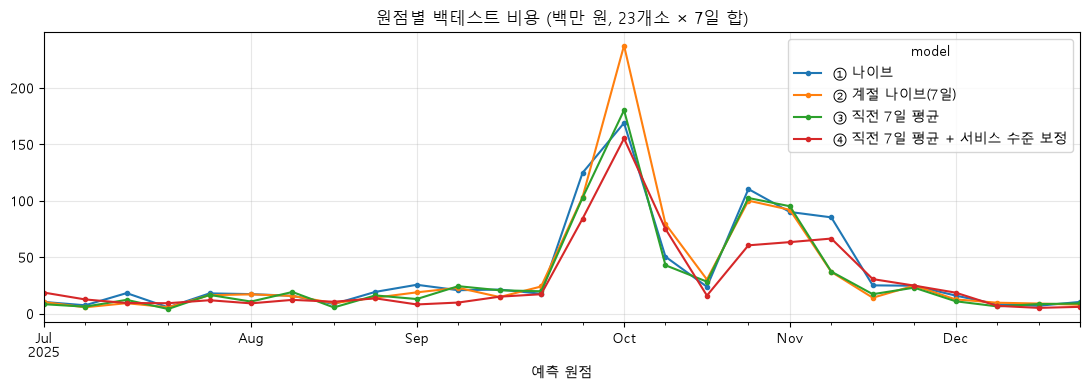

In [13]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'; plt.rcParams['axes.unicode_minus'] = False
ax = per_origin['비용(백만원)'].plot(figsize=(11, 4), marker='o', ms=3)
ax.set_title('원점별 백테스트 비용 (백만 원, 23개소 × 7일 합)'); ax.set_xlabel('예측 원점'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT / 'per_origin_cost.png', dpi=150)

### 유형별 (요구사항 7 미리보기)

In [14]:
d['날짜유형'] = np.select([d['is_free_rule'] == 1, d['is_holiday'] == 1, d['is_offday'] == 1],
                       ['무료개방(규칙)', '공휴일', '주말'], default='평일')
def wape(x): return (x['y'] - x['yhat']).abs().sum() / x['y'].sum()
for key in ['날짜유형', 'group']:
    t = d.groupby([key, 'model']).apply(lambda x: pd.Series({'WAPE': wape(x), '적중률': x['hit'].mean(),
                                                             '비용(백만원)': x['cost'].sum() / 1e6}),
                                        include_groups=False).unstack('model')
    display(t)

WAPE                                                  적중률                                                비용(백만원)                                               
model    ① 나이브 ② 계절 나이브(7일) ③ 직전 7일 평균 ④ 직전 7일 평균 + 서비스 수준 보정 ① 나이브 ② 계절 나이브(7일) ③ 직전 7일 평균 ④ 직전 7일 평균 + 서비스 수준 보정   ① 나이브 ② 계절 나이브(7일) ③ 직전 7일 평균 ④ 직전 7일 평균 + 서비스 수준 보정
날짜유형                                                                                                                                                                     
공휴일      0.254        0.374      0.289                  0.289 0.500        0.130      0.109                  0.522   6.553       10.460      8.183                  4.029
무료개방(규칙) 0.606        0.696      0.589                  0.589 0.291        0.145      0.276                  0.440 310.568      371.675    314.229                242.153
주말       0.431        0.408      0.385                  0.385 0.549        0.540      0.303                  0.634 314.622      234.613    274.403                206.887
평일       0.566        0.570      0.513                  0.513 0.861        0.565      0.814                  0.959 316.674      322.565    241.742                314.744

WAPE                                                  적중률                                                비용(백만원)                                               
model ① 나이브 ② 계절 나이브(7일) ③ 직전 7일 평균 ④ 직전 7일 평균 + 서비스 수준 보정 ① 나이브 ② 계절 나이브(7일) ③ 직전 7일 평균 ④ 직전 7일 평균 + 서비스 수준 보정   ① 나이브 ② 계절 나이브(7일) ③ 직전 7일 평균 ④ 직전 7일 평균 + 서비스 수준 보정
group                                                                                                                                                                 
궁     0.458        0.523      0.446                  0.446 0.519        0.490      0.549                  0.803 719.697      737.324    625.593                566.710
왕릉    0.804        0.500      0.540                  0.540 0.782        0.528      0.612                  0.812 144.253      129.868    139.417                130.040
종묘    0.712        0.844      0.868                  0.868 0.255        0.490      0.599                  0.803  84.468       72.122     73.547                 71.062

In [15]:
# 비용이 어디서 나오나: 직전 7일 평균 비용 중 무료 개방일(규칙) 비중
m = d[d['model'] == '③ 직전 7일 평균']
share = m.groupby('is_free_rule')[['cost']].sum().assign(일수=m.groupby('is_free_rule').size())
share / share.sum()

,cost,일수
is_free_rule,,
0,0.625,0.923
1,0.375,0.077


## 오늘 결론 · 내일 할 일

- 검산 7개 일치, 직접 만든 달력 = 제공 달력(불일치 0칸) → 2026 달력도 같은 함수로 만듦
- 가이드 수치 3개(경복궁 WAPE 50.2%/36.7%, 창덕궁 10-14 비용 1,390,175원) 재현 → 백테스트 틀 검증 완료
- 1순위 지표를 MASE 로 정하고(수업 기준), 특별일 있는 주 / 없는 주로 나눠 봄 — 베이스라인은 특별일 있는 주에서 크게 무너짐
- FVA 1·2행 확보: 직전 7일 평균 vs 서비스 수준 보정. 보정은 점 예측(WAPE)은 그대로 두고 인력만 0.8 분위수 쪽으로 올려 적중률을 0.8 근처로 맞추고 **비용을 줄입니다**. 다만 줄어든 비용은 거의 무료 개방일·공휴일에서 나옵니다(평소 날만 보면 비용이 오히려 늘어남)
- Day 2(`02_day2_models.ipynb`): 글로벌 MLP(분위수 손실, FVA 7변형 × 시드 0~4)와 Chronos-2(제로샷 / + 공변량)를 같은 원점·같은 지표로 FVA 3행부터 채우기